### Random Correlators

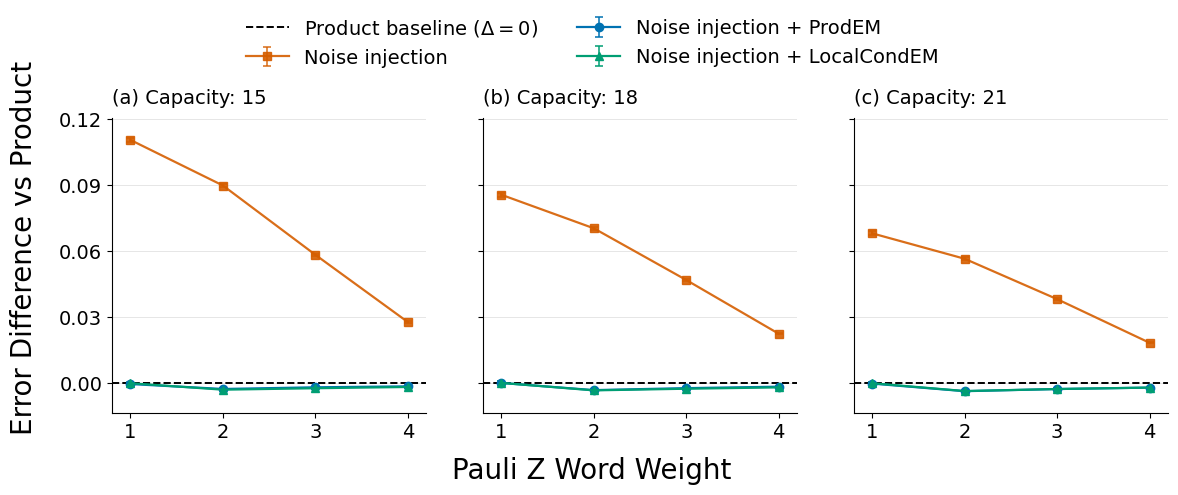

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
import numpy as np
import pandas as pd

results_df = pd.read_csv(
    "./correlator_comparison.csv"
)

MODEL_COL = "model"   # Change if your CSV uses another circuit-ID column.
RUN_COL = "run"

methods = [
    f"{method}_m{capacity}"
    for method in ["DQC", "DQC+ProdEM", "DQC+LocalCondEM"]
    for capacity in [15, 18, 21]
]

models = sorted(results_df[MODEL_COL].unique())
rng = np.random.default_rng(42)
num_bootstrap = 5000

# Use the first 50 Product runs for every capacity.
# Assumes run IDs start at zero within each circuit.
results_df = results_df.loc[
    (results_df["method"] != "Product")
    | (results_df[RUN_COL] < 50)
].copy()


def get_errors(model, method, weight):
    rows = results_df.loc[
        (results_df[MODEL_COL] == model)
        & (results_df["method"] == method)
        & (results_df["weight"] == weight)
    ].sort_values(RUN_COL)

    if rows[RUN_COL].duplicated().any():
        raise ValueError(
            f"Duplicate runs: {model}, {method}, weight {weight}"
        )

    errors = rows["mae"].to_numpy(dtype=float)

    if len(errors) != 50:
        raise ValueError(
            f"Expected 50 runs: {model}, {method}, weight {weight}; "
            f"found {len(errors)}."
        )

    if not np.all(np.isfinite(errors)):
        raise ValueError("Nonfinite MAE values found.")

    return errors


summary_rows = []

for weight in range(1, 5):

    # Bootstrap Product once per weight and reuse across comparisons.
    product_errors = {}
    product_boot_means = {}

    for model in models:
        errors = get_errors(model, "Product", weight)
        product_errors[model] = errors

        indices = rng.integers(
            0, len(errors),
            size=(num_bootstrap, len(errors)),
        )
        product_boot_means[model] = errors[indices].mean(axis=1)

    for method in methods:
        circuit_deltas = []
        boot_delta = np.zeros(num_bootstrap)

        for model in models:
            errors = get_errors(model, method, weight)

            circuit_deltas.append(
                errors.mean() - product_errors[model].mean()
            )

            # Independently resample method repetitions.
            indices = rng.integers(
                0, len(errors),
                size=(num_bootstrap, len(errors)),
            )
            method_boot_means = errors[indices].mean(axis=1)

            boot_delta += (
                method_boot_means - product_boot_means[model]
            ) / len(models)

        summary_rows.append({
            "Correlator": weight,
            "Method": method,
            "Delta Mean": float(np.mean(circuit_deltas)),
            "Delta ci95": np.quantile(
                boot_delta, [0.025, 0.975]
            ),
        })

paper_df = pd.DataFrame(summary_rows)

METHOD_COLORS = {
    "DQC": "#D55E00",             # vermillion
    "DQC+ProdEM": "#0072B2",      # blue
    "DQC+LocalCondEM": "#009E73",   # bluish green
    "Product": "#000000",         # black
    "Bitflip": "#E69F00",         # orange
    "Uniform": "#999999",         # gray
}

METHOD_COLORS = {
    "DQC": "#D55E00",
    "DQC+ProdEM": "#0072B2",
    "DQC+LocalCondEM": "#009E73",
    "Product": "#000000",
}

METHOD_LABELS = {
    "DQC": "Noise injection",
    "DQC+ProdEM": "Noise injection + ProdEM",
    "DQC+LocalCondEM": "Noise injection + LocalCondEM",
}

MARKERS = {
    "DQC": "s",
    "DQC+ProdEM": "o",
    "DQC+LocalCondEM": "^",
}

methods = ["DQC", "DQC+ProdEM", "DQC+LocalCondEM"]
capacities = [15, 18, 21]
weights = [1, 2, 3, 4]

fig, axes = plt.subplots(
    1, 3,
    sharex=True,
    sharey=True,
    figsize=(12, 5),
)

for ci, (ax, capacity) in enumerate(zip(axes, capacities)):
    ax.axhline(
        0,
        color=METHOD_COLORS["Product"],
        linestyle="--",
        linewidth=1.4,
        label=r"Product baseline ($\Delta=0$)",
        zorder=2,
    )

    for method in methods:
        rows = (
            paper_df[
                paper_df["Method"] == f"{method}_m{capacity}"
            ]
            .set_index("Correlator")
            .loc[weights]
        )

        means = rows["Delta Mean"].to_numpy(dtype=float)
        ci95s = np.asarray(rows["Delta ci95"].tolist(), dtype=float)

        yerrs = np.vstack([
            means - ci95s[:, 0],
            ci95s[:, 1] - means,
        ])

        ax.errorbar(
            weights,
            means,
            yerr=yerrs,
            color=METHOD_COLORS[method],
            marker=MARKERS[method],
            markersize=6,
            linewidth=1.6,
            elinewidth=1.1,
            capsize=3,
            capthick=1.1,
            alpha=0.9 if method == "DQC" else 1.0,
            label=METHOD_LABELS[method],
            zorder=3,
        )

    ax.set_title(
        f"({chr(97 + ci)}) Capacity: {capacity}",
        fontsize=14,
        loc="left",
        pad=10,
    )
    ax.set_xlim(0.8, 4.2)
    ax.set_xticks(weights)
    ax.tick_params(axis="both", labelsize=14)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    # Retain negative values and confidence intervals.
    ax.margins(y=0.08)

    ax.set_axisbelow(True)
    ax.grid(axis="y", color="0.90", linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=2,
    frameon=False,
    fontsize=14,
    columnspacing=2.0,
    handlelength=2.2,
)

fig.supxlabel("Pauli Z Word Weight", fontsize=20, y=0.025)
fig.supylabel("Error Difference vs Product", fontsize=20, x=0.015)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.17,
    top=0.76,
    wspace=0.18,
)

# Optional export:
fig.savefig("random_pauli_errors_rnfixed.pdf", bbox_inches="tight")
# fig.savefig("random_pauli_errors.png", dpi=300, bbox_inches="tight")

plt.show()